# Principal Component Analysis

In [49]:
from sklearn.datasets import load_breast_cancer
import numpy as np
from matplotlib import pyplot as plt

In [50]:
data = load_breast_cancer()
x_data = data.data
y_data = data.target

x_data = (x_data - x_data.mean(axis=0))/x_data.std(axis=0)

## Maximum Variance formulation

In [51]:
N = x_data.shape[0]
x_mean = x_data.mean(axis=0)
S = ((x_data - x_mean)[:, None, :] * (x_data - x_mean)[..., None]).mean(axis=0)
evals, evecs = np.linalg.eig(S)

s_evals = np.argsort(evals.real, descending=True)
evec0, evec1 = evecs[s_evals][:2]

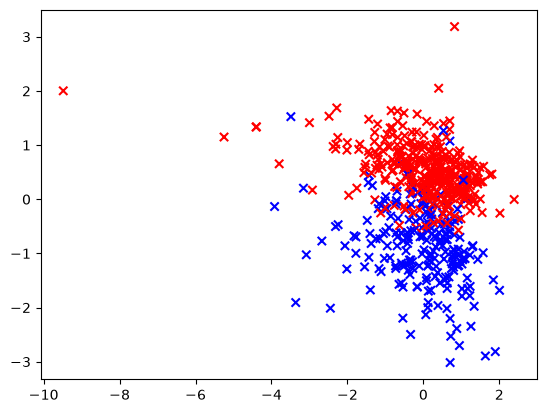

In [52]:
x_comp = (x_data @ evec0).real
y_comp = (x_data @ evec1).real
c = ['blue' if y==0 else 'red' for y in y_data]

plt.scatter(x_comp, y_comp, marker='x', c=c)

## Maximum Likelihood

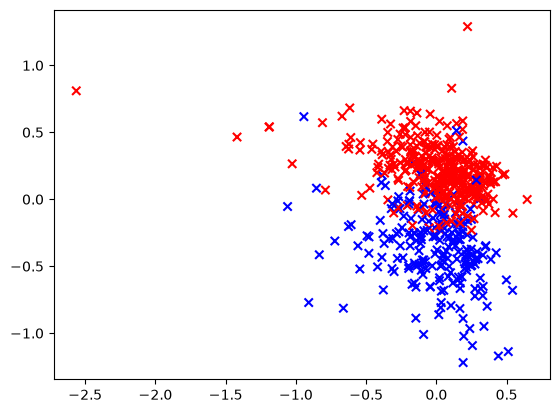

In [72]:
U = evecs[s_evals][:2].T.real
L = np.diag(evals[s_evals][:2].real)
sig_2 = (1/(x_data.shape[1] - 2)) * evals[s_evals][2:].sum().real

D = L - sig_2 * np.eye(L.shape[0])
W_ml = U @ np.sqrt(D)
W_ml.shape
M = W_ml.T @ W_ml + sig_2 * np.eye(W_ml.shape[1])
M_inv = np.linalg.inv(M)

z = (M_inv @ W_ml.T @ (x_data - x_data.mean(axis=0)).T).T

plt.scatter(z[:, 0], z[:, 1], marker='x', c=c)